# Tugas 2: Regresi Deret Waktu (RUL)

**Alur:** 0 Setup → 1 Muat data → 2 Eksplorasi → 3 Label RUL → 4 Preprocessing + window → 5 Split per mesin → 6 Baseline → 7 Model sekuens → 8 Evaluasi → 9 Ketidakpastian → 10 Prediksi CSV

## 0. Setup

In [5]:
import os
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

SEED = 42
RUL_CAP = 150
ID_COL = "id_unit"
CYCLE_COL = "siklus"
SETTING_COLS = ["setel_1", "setel_2", "setel_3"]
SENSOR_COLS = [f"s{i:02d}" for i in range(1, 22)]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def asym_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    diff = y_pred - y_true
    return float(np.sum(np.where(diff < 0, np.exp(-diff / 13.0) - 1.0, np.exp(diff / 10.0) - 1.0)))


def add_rul(df, id_col=ID_COL, cycle_col=CYCLE_COL, cap=RUL_CAP):
    out = df.copy()
    rul = out.groupby(id_col)[cycle_col].transform("max") - out[cycle_col]
    if cap is not None:
        rul = rul.clip(upper=cap)
    out["rul"] = rul
    return out


class Preprocessor:
    def __init__(self, feature_cols=None):
        self.feature_cols = feature_cols
        self.scaler = StandardScaler()
        self.fitted = False

    def fit(self, df, feature_cols=None):
        cols = feature_cols if feature_cols is not None else self.feature_cols
        if cols is None:
            exclude = {ID_COL, CYCLE_COL, "rul", "RUL"}
            cols = [c for c in df.columns if c not in exclude and pd.api.types.is_numeric_dtype(df[c])]
        self.feature_cols = list(cols)
        self.scaler.fit(df[self.feature_cols].fillna(0.0).values)
        self.fitted = True
        return self

    def transform(self, df):
        if not self.fitted:
            raise RuntimeError("Preprocessor belum di-fit.")
        out = df.copy()
        out[self.feature_cols] = self.scaler.transform(out[self.feature_cols].fillna(0.0).values)
        return out

    def fit_transform(self, df, feature_cols=None):
        self.fit(df, feature_cols=feature_cols)
        return self.transform(df)


def make_windows(df, seq_len=30, feature_cols=None, target_col="rul", id_col=ID_COL, cycle_col=CYCLE_COL):
    if feature_cols is None:
        exclude = {id_col, cycle_col, target_col, "RUL"}
        feature_cols = [c for c in df.columns if c not in exclude and pd.api.types.is_numeric_dtype(df[c])]

    X_list, y_list, ids_list = [], [], []
    for unit_id, grp in df.sort_values([id_col, cycle_col]).groupby(id_col):
        feats = grp[feature_cols].values.astype(np.float32)
        if len(feats) < seq_len:
            feats = np.vstack([np.repeat(feats[:1], seq_len - len(feats), axis=0), feats])
        for start in range(len(feats) - seq_len + 1):
            X_list.append(feats[start:start + seq_len])
            if target_col in grp.columns:
                targets = grp[target_col].values.astype(np.float32)
                if len(targets) < seq_len:
                    targets = np.pad(targets, (seq_len - len(targets), 0), mode="edge")
                y_list.append(targets[start + seq_len - 1])
            ids_list.append(unit_id)

    X = np.array(X_list, dtype=np.float32) if X_list else np.empty((0, seq_len, len(feature_cols)), dtype=np.float32)
    y = np.array(y_list, dtype=np.float32) if y_list else np.empty((0,), dtype=np.float32)
    return X, y, np.array(ids_list)


def build_windows(train_df, val_df=None, test_df=None, seq_len=30, feature_cols=None, target_col="rul"):
    res = {"train": make_windows(train_df, seq_len=seq_len, feature_cols=feature_cols, target_col=target_col)}
    if val_df is not None:
        res["val"] = make_windows(val_df, seq_len=seq_len, feature_cols=feature_cols, target_col=target_col)
    if test_df is not None:
        res["test"] = make_windows(test_df, seq_len=seq_len, feature_cols=feature_cols, target_col=target_col)
    return res


set_seed(SEED)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
try:
    import torch
    print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())
except ImportError:
    print("torch belum terpasang (dibutuhkan mulai bagian 7)")

python 3.13.0 | numpy 2.2.1 | pandas 3.1.1
torch 2.15.0+cpu | cuda: False


## 1. Muat data
- [ ] Kolom sesuai `kamus_data.md`: `id_unit`, `siklus`, `setel_1..3`, `s01..s21`

In [6]:
DATA_DIR = '../../data/data_uts_dl'
train = pd.read_csv(f'{DATA_DIR}/rul_train.csv.gz')
test  = pd.read_csv(f'{DATA_DIR}/rul_test.csv.gz')

need = [ID_COL, CYCLE_COL] + SETTING_COLS + SENSOR_COLS
assert all(c in train.columns for c in need), set(need) - set(train.columns)
assert all(c in test.columns for c in need), set(need) - set(test.columns)
print('train', train.shape, '| mesin:', train[ID_COL].nunique())
print('test ', test.shape,  '| mesin:', test[ID_COL].nunique())
train.head()

train (254174, 26) | mesin: 900
test  (51692, 26) | mesin: 300


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,3,1,20.001,0.7005,100.0,1107.746,569.289,991.700,1099.533,NaN,...,1092.248,1144.779,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003
1,3,2,34.996,0.8424,100.0,1071.040,587.821,1013.673,NaN,157.684,...,1095.511,1167.320,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368
2,3,3,0.001,-0.0012,100.0,1130.132,585.094,998.221,1127.436,161.918,...,1091.245,1170.340,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443
3,3,4,35.001,0.8375,100.0,1080.962,585.775,1016.998,1152.147,NaN,...,1096.911,1173.207,1348.423,877.459,784.038,399.505,978.649,813.737,1113.184,411.554
4,3,5,9.998,0.2483,100.0,1095.013,580.506,997.108,1119.245,169.359,...,1102.956,1159.881,1341.195,872.265,772.284,NaN,950.568,821.425,969.681,362.551


## 2. Eksplorasi 
- [ ] 2a Panjang riwayat  - [ ] 2b Missing value  - [ ] 2c Sensor tidak informatif  - [ ] 2d Operating settings  - [ ] 2e Spike

Catat temuan tiap sel (3-5 kalimat total) untuk laporan.

### 2a. Panjang riwayat dan keberurutan siklus

Panjang riwayat train:
 count    900.0
mean     282.4
std       84.6
min      133.0
25%      224.0
50%      265.0
75%      323.0
max      778.0
Name: siklus, dtype: float64
Panjang riwayat test :
 count    300.0
mean     172.3
std       72.7
min       50.0
25%      117.0
50%      162.5
75%      212.0
max      455.0
Name: siklus, dtype: float64
mulai dari 1: 1.0 | tanpa lubang: 1.0
duplikat (id, siklus): 0


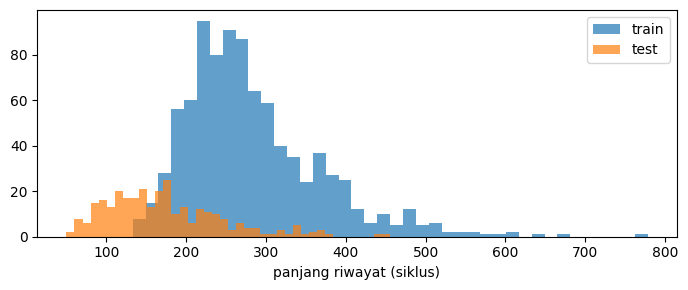

In [7]:
len_tr = train.groupby(ID_COL)[CYCLE_COL].max()
len_te = test.groupby(ID_COL)[CYCLE_COL].max()
print('Panjang riwayat train:\n', len_tr.describe().round(1))
print('Panjang riwayat test :\n', len_te.describe().round(1))

# siklus mulai dari 1 dan tanpa lubang?
g = train.groupby(ID_COL)[CYCLE_COL]
print('mulai dari 1:', (g.min() == 1).mean(), '| tanpa lubang:', ((g.max() - g.min() + 1) == g.count()).mean())
print('duplikat (id, siklus):', train.duplicated([ID_COL, CYCLE_COL]).sum())

plt.figure(figsize=(7, 3)); plt.hist(len_tr, bins=40, alpha=.7, label='train'); plt.hist(len_te, bins=40, alpha=.7, label='test')
plt.xlabel('panjang riwayat (siklus)'); plt.legend(); plt.tight_layout(); plt.show()

### 2b. Missing value

s01    2.00
s02    2.07
s03    2.01
s04    2.05
s05    2.01
s06    2.06
s07    2.05
s08    2.02
s09    2.04
s10    2.02
s11    1.98
s12    2.04
s13    2.03
s14    1.99
s15    2.02
s16    2.00
s17    2.01
s18    2.06
s19    2.03
s20    2.11
s21    1.97
baris dengan >=1 NaN: 35.03%
NaN pada setel_*: 0


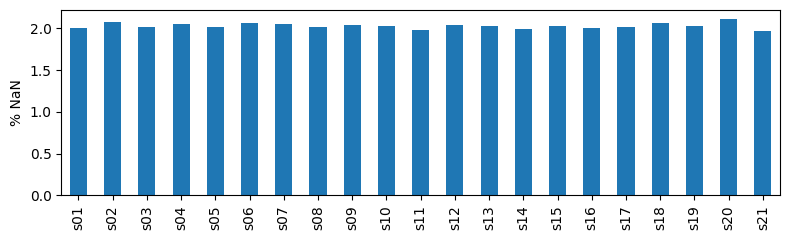

In [8]:
na = train[SENSOR_COLS].isna().mean() * 100
print(na[na > 0].round(2).to_string() or 'tidak ada NaN')
print('baris dengan >=1 NaN: %.2f%%' % (train[SENSOR_COLS].isna().any(axis=1).mean() * 100))
print('NaN pada setel_*:', train[SETTING_COLS].isna().sum().sum())
na.plot.bar(figsize=(8, 2.5), ylabel='% NaN'); plt.tight_layout(); plt.show()

### 2c. Sensor tidak informatif
Sensor dengan variasi nol (atau hampir nol) tidak membawa informasi. Variasi dicek global, lalu di bagian 3 dicek korelasinya dengan RUL.

In [9]:
desc = train[SENSOR_COLS].describe().T[['mean', 'std', 'min', 'max']]
desc['nunique'] = train[SENSOR_COLS].nunique()
desc['std/|mean|'] = desc['std'] / desc['mean'].abs().replace(0, np.nan)
print(desc.round(4).to_string())
const = desc.index[(desc['std'] < 1e-8) | (desc['nunique'] <= 1)].tolist()
print('\nSensor konstan:', const)

          mean      std       min       max  nunique  std/|mean|
s01  1101.6462  17.7601  1042.699  1161.239    66416      0.0161
s02   579.5977  15.9287   537.791   619.762    49790      0.0275
s03  1005.4943  23.0536   943.024  1081.733    73424      0.0229
s04  1133.4760  17.6248  1079.085  1196.050    66366      0.0155
s05   168.5448   9.4889   156.897   187.159     4860      0.0563
s06  1310.5447   8.6946  1267.150  1358.938    39558      0.0066
s07   723.6262   6.8274   683.143   754.713    33031      0.0094
s08   779.3535   6.8589   750.189   810.489    33082      0.0088
s09   498.0118  25.1573   444.323   543.874    39186      0.0505
s10   803.3197  17.4156   771.549   839.647    34473      0.0217
s11  1492.4330  16.1348  1420.981  1559.755    67979      0.0108
s12  1099.5628   6.2962  1084.719  1116.852    22551      0.0057
s13  1172.3870  26.3306  1085.904  1250.481    83399      0.0225
s14  1339.6213  15.7756  1278.019  1395.817    62217      0.0118
s15   878.6444   8.3046  

### 2d. Operating settings
Jika `setel_*` hanya mengambil beberapa kombinasi, itu adalah kondisi operasi diskret. Nilai sensor bisa bergeser mengikuti kondisi, sehingga perlu dinormalisasi per kondisi.

           setel_1      setel_2      setel_3
count  254174.0000  254174.0000  254174.0000
mean       22.0233       0.5422      93.3571
std        14.2101       0.3130      14.8858
min        -0.0080      -0.0075      60.0000
25%        10.0000       0.2500     100.0000
50%        24.9930       0.6953     100.0000
75%        35.0000       0.8387     100.0000
max        42.0080       0.8487     100.0000
kombinasi unik (dibulatkan 3 desimal): 1222


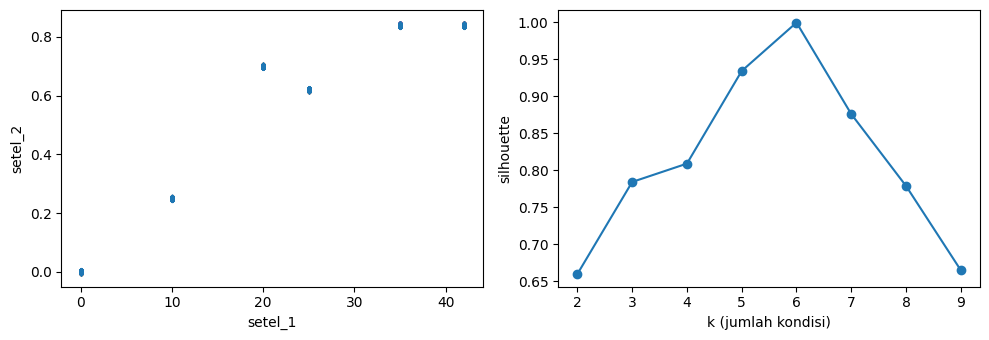

k dengan silhouette tertinggi: 6


In [10]:
print(train[SETTING_COLS].describe().round(4).to_string())
print('kombinasi unik (dibulatkan 3 desimal):', train[SETTING_COLS].round(3).drop_duplicates().shape[0])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(train[SETTING_COLS[0]], train[SETTING_COLS[1]], s=2, alpha=.3); ax[0].set_xlabel(SETTING_COLS[0]); ax[0].set_ylabel(SETTING_COLS[1])
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
sub = train[SETTING_COLS].dropna().sample(min(20000, len(train)), random_state=SEED).to_numpy()
ks = range(2, 10); sil = [silhouette_score(sub, KMeans(k, n_init=5, random_state=SEED).fit_predict(sub), sample_size=5000, random_state=SEED) for k in ks]
ax[1].plot(list(ks), sil, marker='o'); ax[1].set_xlabel('k (jumlah kondisi)'); ax[1].set_ylabel('silhouette'); plt.tight_layout(); plt.show()
print('k dengan silhouette tertinggi:', list(ks)[int(np.argmax(sil))])

In [11]:
# Seberapa kuat pengaruh settings pada sensor? (korelasi absolut maksimum tiap sensor dengan setel_*)
corr = train[SETTING_COLS + SENSOR_COLS].corr().loc[SENSOR_COLS, SETTING_COLS].abs()
print(corr.max(axis=1).sort_values(ascending=False).head(10).round(3).to_string())

s19    0.850
s03    0.834
s05    0.832
s18    0.821
s02    0.762
s14    0.706
s13    0.691
s01    0.682
s09    0.629
s12    0.533


### 2e. Spike
Spike = lonjakan sesaat yang bukan bagian dari degradasi. Dideteksi dengan z-score robust (median dan MAD) per sensor dan per mesin.

% baris dengan |z robust| > 6 per sensor (tinggi = banyak lonjakan / tren kuat):
s20    4.98
s16    0.00
s06    0.00
s13    0.00
s01    0.00
s05    0.00
s04    0.00
s03    0.00
s02    0.00
s09    0.00


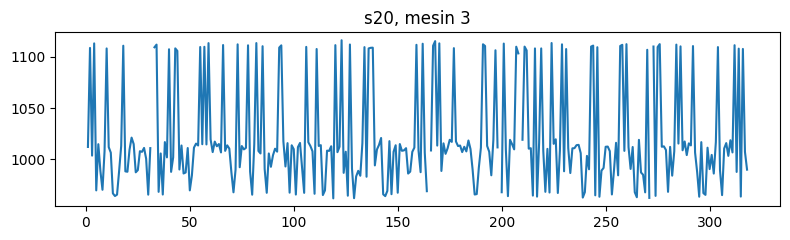

In [12]:
def spike_rate(df, thr=6):
    x = df[SENSOR_COLS]
    med = x.groupby(df[ID_COL]).transform('median')
    mad = (x - med).abs().groupby(df[ID_COL]).transform('median') * 1.4826
    z = (x - med) / mad.replace(0, np.nan)
    return (z.abs() > thr).mean() * 100
sr = spike_rate(train)
print('% baris dengan |z robust| > 6 per sensor (tinggi = banyak lonjakan / tren kuat):')
print(sr.sort_values(ascending=False).head(10).round(2).to_string())

u = train[ID_COL].iloc[0]; s = sr.sort_values(ascending=False).index[0]
d = train[train[ID_COL] == u]; plt.figure(figsize=(8, 2.5)); plt.plot(d[CYCLE_COL], d[s]); plt.title(f'{s}, mesin {u}'); plt.tight_layout(); plt.show()

## 3. Label RUL, cap 150 
RUL = min(siklus_terakhir − siklus, 150). Di data latih, siklus terakhir adalah saat rusak. Data uji tidak diberi label; prediksi dibuat pada siklus terakhir tiap mesin.

- [ ] Label benar (plot datar di 150 lalu turun linear sampai 0)
- [ ] Korelasi sensor dengan RUL untuk menentukan sensor informatif

% baris yang kena cap: 46.9


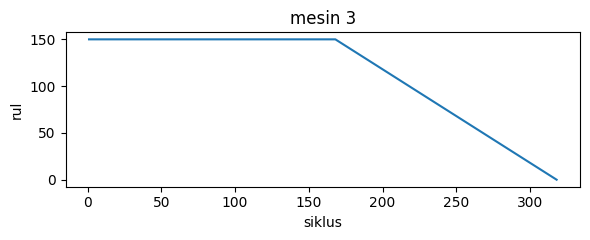

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

ID_COL = "id_unit"
CYCLE_COL = "siklus"
RUL_CAP = 150


def add_rul(df, id_col=ID_COL, cycle_col=CYCLE_COL, cap=RUL_CAP):
    out = df.copy()
    max_cycle = out.groupby(id_col)[cycle_col].transform("max")
    rul = max_cycle - out[cycle_col]
    if cap is not None:
        rul = rul.clip(upper=cap)
    out["rul"] = rul
    return out


train = add_rul(train)

assert train.groupby(ID_COL)["rul"].min().eq(0).all()  # tiap mesin berakhir di RUL 0
assert train["rul"].max() == RUL_CAP
print("% baris yang kena cap:", round((train["rul"] == RUL_CAP).mean() * 100, 1))

u = train[ID_COL].iloc[0]
d = train[train[ID_COL] == u]
plt.figure(figsize=(6, 2.5))
plt.plot(d[CYCLE_COL], d["rul"])
plt.xlabel("siklus")
plt.ylabel("rul")
plt.title(f"mesin {u}")
plt.tight_layout()
plt.show()

In [ ]:
# Sensor mana yang berhubungan dengan degradasi? (Spearman terhadap RUL, hanya baris RUL < cap)
deg = train[train['RUL'] < RUL_CAP]
rho = deg[SENSOR_COLS].corrwith(deg['RUL'], method='spearman').abs().sort_values(ascending=False)
print(rho.round(3).to_string())
weak = rho[rho < 0.1].index.tolist(); print('\nKandidat sensor tidak informatif (|rho| < 0.1):', weak)

s15    0.364
s07    0.325
s04    0.314
s03    0.181
s12    0.173
s14    0.134
s02    0.134
s11    0.134
s08    0.127
s13    0.117
s17    0.096
s20    0.075
s09    0.055
s21    0.038
s05    0.002
s01    0.001
s18    0.001
s16    0.000
s19    0.000
s10    0.000
s06    0.000

Kandidat sensor tidak informatif (|rho| < 0.1): ['s17', 's20', 's09', 's21', 's05', 's01', 's18', 's16', 's19', 's10', 's06']


## 4. Preprocessing dan sliding window 
`Preprocessor` mengisi NaN (forward-fill per mesin, hanya masa lalu), menormalisasi per kondisi operasi, membuang sensor konstan, dan meredam spike (clip ±5σ). Statistik di-fit **hanya pada data train**. `build_windows` membuat window yang hanya melihat masa lalu.

- [ ] Isi `N_COND` dan `DROP_SENSORS` dari hasil bagian 2 dan 3
- [ ] Tes kebocoran lolos

In [ ]:
N_COND = 6            # 6 kondisi operasi (silhouette tertinggi di k=6, lihat 2d)
DROP_SENSORS = []     # sensor tambahan yang dibuang (dari 2c / 3)
WINDOW = 30
STRIDE = 1            # naikkan ke 2-3 bila memori kurang

# demo pada 5 mesin: bentuk fitur dan window
demo = train[train[ID_COL].isin(train[ID_COL].unique()[:5])]
p = Preprocessor(n_cond=N_COND, drop=DROP_SENSORS).fit(demo)
d, F = p.transform(demo)
Xw, yw, uw = build_windows(d, F, WINDOW, STRIDE)
print('fitur:', len(p.feature_names), '| window:', Xw.shape, '| label:', yw.shape)

# tes kebocoran: ubah siklus terakhir sebuah mesin -> window sebelumnya tidak boleh berubah
d2 = d.copy(); i = np.flatnonzero(d2[ID_COL].to_numpy() == d2[ID_COL].iloc[0])[-1]
F2 = F.copy(); F2[i] = 99
X1, _, _ = build_windows(d, F, WINDOW, 1); X2, _, _ = build_windows(d2, F2, WINDOW, 1)
n_unit0 = (d[ID_COL] == d[ID_COL].iloc[0]).sum()
assert np.array_equal(X1[:n_unit0 - 1], X2[:n_unit0 - 1]); print('tes kebocoran lolos')

fitur: 24 | window: (1597, 30, 24) | label: (1597,)
tes kebocoran lolos


## 5. Split validasi per mesin 
Mesin dipisah, bukan baris. Normalisasi di-fit hanya pada mesin train.

- [ ] Tidak ada mesin yang muncul di train dan val sekaligus

In [ ]:
units = train[ID_COL].unique()
perm = np.random.RandomState(SEED).permutation(units)
n_val = int(0.2 * len(units))
val_units, tr_units = perm[:n_val], perm[n_val:]
assert not set(val_units) & set(tr_units)
print('mesin train:', len(tr_units), '| mesin val:', len(val_units))

tr_df, va_df = train[train[ID_COL].isin(tr_units)], train[train[ID_COL].isin(val_units)]
prep = Preprocessor(n_cond=N_COND, drop=DROP_SENSORS).fit(tr_df)      # fit hanya pada train
d_tr, F_tr = prep.transform(tr_df); d_va, F_va = prep.transform(va_df)
X_tr, y_tr, u_tr = build_windows(d_tr, F_tr, WINDOW, STRIDE)
X_va, y_va, u_va = build_windows(d_va, F_va, WINDOW, 1)
print('X_tr', X_tr.shape, '(%.2f GB)' % (X_tr.nbytes / 1e9), '| X_va', X_va.shape)
print('fitur:', prep.feature_names)
print('RUL rata-rata train/val:', y_tr.mean().round(1), y_va.mean().round(1))

mesin train: 720 | mesin val: 180
X_tr (203784, 30, 24) (0.59 GB) | X_va (50390, 30, 24)
fitur: ['s01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 'setel_1', 'setel_2', 'setel_3']
RUL rata-rata train/val: 110.0 109.5


## 6. Baseline non-deep-learning 
Fitur ringkas tiap window (mean, std, nilai terakhir, selisih akhir−awal) lalu Ridge dan Gradient Boosting. Dipakai sebagai pembanding model deep learning.

- [ ] Baseline jalan dan hasilnya tercatat di tabel `results`

In [ ]:
import os, time
os.makedirs('hasil', exist_ok=True)
results = {}          # nama -> {'RMSE', 'skor_rata2'}
predict_fns = {}      # nama -> fungsi(X) -> prediksi RUL (0..150)

def summarize(X):
    """(N, T, F) -> (N, 4F): mean, std, nilai terakhir, selisih akhir-awal."""
    return np.concatenate([X.mean(1), X.std(1), X[:, -1], X[:, -1] - X[:, 0]], axis=1)

def evaluate(name, y, p):
    p = np.clip(p, 0, RUL_CAP)
    results[name] = {'RMSE': rmse(y, p), 'skor_rata2': asym_score(y, p) / len(y)}
    print(f"{name:<22} RMSE = {results[name]['RMSE']:.2f} | skor asimetris rata-rata/sampel = {results[name]['skor_rata2']:.3f}")

S_tr, S_va = summarize(X_tr), summarize(X_va)
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

ridge = Ridge(alpha=1.0).fit(S_tr, y_tr)
predict_fns['Ridge'] = lambda X: np.clip(ridge.predict(summarize(X)), 0, RUL_CAP)
evaluate('Ridge', y_va, predict_fns['Ridge'](X_va))

t0 = time.time()
gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED).fit(S_tr, y_tr)
predict_fns['GradBoost'] = lambda X: np.clip(gb.predict(summarize(X)), 0, RUL_CAP)
evaluate('GradBoost', y_va, predict_fns['GradBoost'](X_va)); print('waktu: %.0f detik' % (time.time() - t0))

Ridge                  RMSE = 23.51 | skor asimetris rata-rata/sampel = 35.057
GradBoost              RMSE = 21.74 | skor asimetris rata-rata/sampel = 37.495
waktu: 11 detik


## 7. Model sekuens 
Dua arsitektur: **GRU** (rekuren) dan **1D-CNN** (konvolusi sepanjang waktu).

Konfigurasi (catat untuk laporan): loss = MSE pada RUL/150, optimizer = Adam (lr 1e-3, weight decay 1e-5), batch 512, early stopping pada RMSE val (sabar 4 epoch), bobot terbaik disimpan di `hasil/`.

- [x] Model 1: GRU
- [x] Model 2: 1D-CNN
- [ ] Kurva loss train vs val tersimpan di `hasil/` (cek setelah training)

GRU epoch 01 | loss train 0.0558 | loss val 0.0229 | RMSE val 22.72 | 56s
GRU epoch 02 | loss train 0.0287 | loss val 0.0222 | RMSE val 22.37 | 57s
GRU epoch 03 | loss train 0.0253 | loss val 0.0193 | RMSE val 20.82 | 55s
GRU epoch 04 | loss train 0.0222 | loss val 0.0193 | RMSE val 20.85 | 60s
GRU epoch 05 | loss train 0.0199 | loss val 0.0196 | RMSE val 21.00 | 62s
GRU epoch 06 | loss train 0.0180 | loss val 0.0207 | RMSE val 21.60 | 57s
GRU epoch 07 | loss train 0.0163 | loss val 0.0193 | RMSE val 20.83 | 61s
early stopping


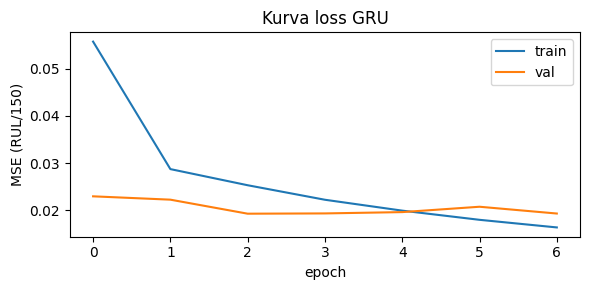

GRU                    RMSE = 20.82 | skor asimetris rata-rata/sampel = 29.919


In [ ]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
EPOCHS, PATIENCE, BATCH, LR = 15, 4, 512, 1e-3     # CPU lambat: turunkan EPOCHS atau naikkan STRIDE di bagian 4
N_FEAT = X_tr.shape[2]

class GRUNet(nn.Module):
    def __init__(self, n_feat, hidden=64, p=0.2):
        super().__init__()
        self.gru = nn.GRU(n_feat, hidden, num_layers=2, batch_first=True, dropout=p)
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(p), nn.Linear(32, 1))
    def forward(self, x):                       # x: (B, T, F)
        o, _ = self.gru(x)
        return self.head(o[:, -1]).squeeze(-1)

class CNN1D(nn.Module):
    def __init__(self, n_feat, window=WINDOW, ch=64, p=0.2):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(n_feat, ch, 5, padding=2), nn.ReLU(),
                                  nn.Conv1d(ch, ch, 5, padding=2), nn.ReLU(), nn.Dropout(p))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(ch * window, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.conv(x.transpose(1, 2))).squeeze(-1)

@torch.no_grad()
def predict_torch(model, X, bs=4096):
    model.eval().to(DEVICE)
    out = [model(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu().numpy() for i in range(0, len(X), bs)]
    return np.clip(np.concatenate(out) * RUL_CAP, 0, RUL_CAP)

def train_model(model, name, seed=SEED):
    set_seed(seed); model.to(DEVICE)
    dl = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy((y_tr / RUL_CAP).astype(np.float32))),
                    batch_size=BATCH, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5); lossf = nn.MSELoss()
    hist, best, best_state, bad = [], 1e9, None, 0
    for ep in range(1, EPOCHS + 1):
        model.train(); tot = 0; t0 = time.time()
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = lossf(model(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        pv = predict_torch(model, X_va); v_rmse = rmse(y_va, pv)
        hist.append((tot / len(dl.dataset), np.mean(((pv - y_va) / RUL_CAP) ** 2), v_rmse))
        print(f"{name} epoch {ep:02d} | loss train {hist[-1][0]:.4f} | loss val {hist[-1][1]:.4f} | RMSE val {v_rmse:.2f} | {time.time()-t0:.0f}s")
        if v_rmse < best - 1e-3: best, bad, best_state = v_rmse, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print('early stopping'); break
    model.load_state_dict(best_state); torch.save(best_state, f'hasil/{name}.pt')
    h = np.array(hist); plt.figure(figsize=(6, 3)); plt.plot(h[:, 0], label='train'); plt.plot(h[:, 1], label='val')
    plt.xlabel('epoch'); plt.ylabel('MSE (RUL/150)'); plt.title(f'Kurva loss {name}'); plt.legend(); plt.tight_layout()
    plt.savefig(f'hasil/kurva_loss_{name}.png', dpi=130); plt.show()
    return model

models = {}
models['GRU'] = train_model(GRUNet(N_FEAT), 'GRU')
predict_fns['GRU'] = lambda X: predict_torch(models['GRU'], X)
evaluate('GRU', y_va, predict_fns['GRU'](X_va))

CNN1D epoch 01 | loss train 0.0337 | loss val 0.0272 | RMSE val 24.75 | 20s
CNN1D epoch 02 | loss train 0.0220 | loss val 0.0234 | RMSE val 22.93 | 21s
CNN1D epoch 03 | loss train 0.0167 | loss val 0.0867 | RMSE val 44.18 | 19s
CNN1D epoch 04 | loss train 0.0149 | loss val 0.0238 | RMSE val 23.13 | 18s
CNN1D epoch 05 | loss train 0.0118 | loss val 0.0270 | RMSE val 24.63 | 18s
CNN1D epoch 06 | loss train 0.0102 | loss val 0.0270 | RMSE val 24.67 | 18s
early stopping


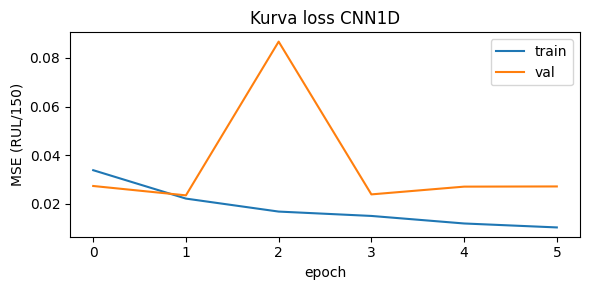

CNN1D                  RMSE = 22.93 | skor asimetris rata-rata/sampel = 29.898


In [ ]:
models['CNN1D'] = train_model(CNN1D(N_FEAT), 'CNN1D')
predict_fns['CNN1D'] = lambda X: predict_torch(models['CNN1D'], X)
evaluate('CNN1D', y_va, predict_fns['CNN1D'](X_va))

## 8. Evaluasi 
Metrik: RMSE dan skor asimetris (prediksi terlalu optimis dihukum lebih berat). Skor asimetris dibagi jumlah sampel agar bisa dibandingkan; skor total di test = jumlah atas 300 mesin.

- [ ] Tabel perbandingan lengkap  - [ ] Model terbaik dipilih dan alasannya ditulis

GRU+CNN1D (rata2)      RMSE = 21.38 | skor asimetris rata-rata/sampel = 26.987
                     RMSE  skor_rata2  est. skor total 300 mesin
GRU                20.815      29.919                   8975.766
GRU+CNN1D (rata2)  21.384      26.987                   8095.997
GradBoost          21.737      37.495                  11248.634
CNN1D              22.932      29.898                   8969.473
Ridge              23.507      35.057                  10516.974

Model terbaik (RMSE val terendah): GRU


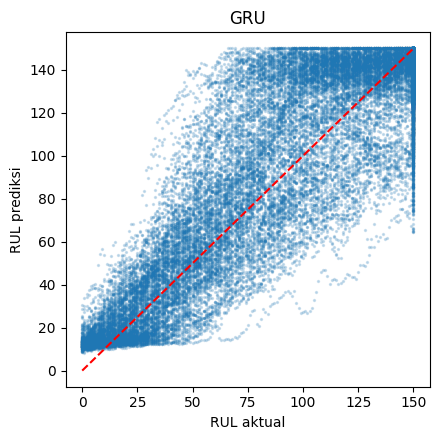

In [ ]:
predict_fns['GRU+CNN1D'] = lambda X: (predict_fns['GRU'](X) + predict_fns['CNN1D'](X)) / 2
evaluate('GRU+CNN1D (rata2)', y_va, predict_fns['GRU+CNN1D'](X_va))

tab = pd.DataFrame(results).T
tab['est. skor total 300 mesin'] = tab['skor_rata2'] * 300
tab = tab.sort_values('RMSE'); print(tab.round(3).to_string())
tab.to_csv('hasil/perbandingan_model.csv')

best_name = tab.index[0].replace(' (rata2)', ''); print('\nModel terbaik (RMSE val terendah):', best_name)
p = predict_fns[best_name](X_va)
plt.figure(figsize=(4.5, 4.5)); plt.scatter(y_va, p, s=2, alpha=.2); plt.plot([0, RUL_CAP], [0, RUL_CAP], 'r--')
plt.xlabel('RUL aktual'); plt.ylabel('RUL prediksi'); plt.title(best_name); plt.tight_layout(); plt.savefig('hasil/scatter_terbaik.png', dpi=130); plt.show()

In [ ]:
# OPSIONAL: skor asimetris menghukum prediksi terlalu optimis lebih berat. Geser prediksi ke bawah sebesar k siklus?
for k in [0, 2, 4, 6, 8, 10]:
    pk = np.clip(p - k, 0, RUL_CAP)
    print(f'geser -{k:>2}: RMSE {rmse(y_va, pk):6.2f} | skor rata-rata/sampel {asym_score(y_va, pk) / len(y_va):7.3f}')
# Pilih k kecil yang menurunkan skor tanpa menaikkan RMSE terlalu banyak, lalu isi SHIFT di bagian 10.

geser - 0: RMSE  20.82 | skor rata-rata/sampel  29.919
geser - 2: RMSE  20.88 | skor rata-rata/sampel  25.533
geser - 4: RMSE  21.14 | skor rata-rata/sampel  22.153
geser - 6: RMSE  21.58 | skor rata-rata/sampel  19.630
geser - 8: RMSE  22.19 | skor rata-rata/sampel  17.852
geser -10: RMSE  22.97 | skor rata-rata/sampel  16.729


## 9. Ketidakpastian 
**MC dropout** pada model deep learning terbaik: dropout tetap aktif saat prediksi, diulang 30 kali, lalu diambil rata-rata dan simpangan baku. Interval = rata-rata ± 2 simpangan baku.

- [ ] Cakupan interval dicek  - [ ] Diskusi kapan mesin diservis ditulis di laporan

model: GRU | rata-rata simpangan baku: 10.13 siklus
cakupan interval mean ± 2sd: 71.5% (idealnya mendekati 95%)
korelasi sd vs |galat|: 0.207
prediksi rata-rata <= 30       | terdeteksi  77.8% mesin berbahaya | alarm palsu   2.2%
batas bawah (mean-2sd) <= 30   | terdeteksi  93.0% mesin berbahaya | alarm palsu   5.1%


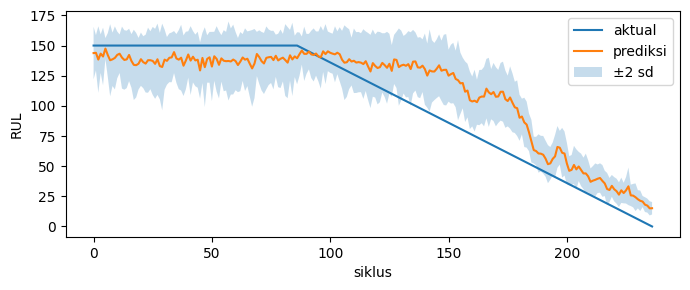

In [ ]:
dl_name = 'GRU' if results['GRU']['RMSE'] <= results['CNN1D']['RMSE'] else 'CNN1D'
mdl = models[dl_name]

@torch.no_grad()
def mc_predict(model, X, T=30, bs=4096):
    model.to(DEVICE).train()                    # train() = dropout aktif (tidak ada batchnorm di model ini)
    runs = [np.concatenate([model(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu().numpy() for i in range(0, len(X), bs)]) for _ in range(T)]
    model.eval(); r = np.clip(np.stack(runs) * RUL_CAP, 0, RUL_CAP)
    return r.mean(0), r.std(0)

set_seed(SEED)
sel = np.random.RandomState(SEED).choice(len(X_va), min(10000, len(X_va)), replace=False)
mu, sd = mc_predict(mdl, X_va[sel]); yv = y_va[sel]
lo, hi = mu - 2 * sd, mu + 2 * sd
print(f'model: {dl_name} | rata-rata simpangan baku: {sd.mean():.2f} siklus')
print(f'cakupan interval mean ± 2sd: {np.mean((yv >= lo) & (yv <= hi)) * 100:.1f}% (idealnya mendekati 95%)')
print('korelasi sd vs |galat|:', np.corrcoef(sd, np.abs(mu - yv))[0, 1].round(3))

# Kapan mesin sebaiknya diservis? Ambang bahaya: RUL <= 30 siklus
TH = 30; danger = yv <= TH
for nama, flag in [('prediksi rata-rata <= 30', mu <= TH), ('batas bawah (mean-2sd) <= 30', lo <= TH)]:
    print(f'{nama:<30} | terdeteksi {flag[danger].mean() * 100:5.1f}% mesin berbahaya | alarm palsu {flag[~danger].mean() * 100:5.1f}%')

# Satu mesin val: prediksi + pita ketidakpastian sepanjang umur
u0 = va_df[ID_COL].unique()[0]; m = u_va == u0
mu_u, sd_u = mc_predict(mdl, X_va[m]); ya = y_va[m]
plt.figure(figsize=(7, 3)); plt.plot(ya, label='aktual'); plt.plot(mu_u, label='prediksi')
plt.fill_between(range(len(mu_u)), mu_u - 2 * sd_u, mu_u + 2 * sd_u, alpha=.25, label='±2 sd')
plt.xlabel('siklus'); plt.ylabel('RUL'); plt.legend(); plt.tight_layout(); plt.savefig('hasil/uncertainty_satu_mesin.png', dpi=130); plt.show()

## 10. Prediksi untuk `prediksi_rul.csv` 
Satu baris per mesin test pada siklus terakhirnya. Fitur test memakai `prep` yang sama dengan saat model dilatih.

- [ ] File dibuat  - [ ] Pengecekan format lolos (300 baris, kolom `id_unit,rul`, nilai 0-150)

In [ ]:
FINAL_MODEL = best_name      # bisa diganti manual, mis. 'GRU+CNN1D' atau 'GRU'
SHIFT = 0                    # isi dari hasil sel opsional bagian 8 bila dipakai (0 = tanpa geser)

d_te, F_te = prep.transform(test)                       # prep di-fit pada train (sama dengan saat training)
X_te, _, u_te = build_windows(d_te, F_te, WINDOW, last_only=True)
pred = np.clip(predict_fns[FINAL_MODEL](X_te) - SHIFT, 0, RUL_CAP)
df_pred = pd.DataFrame({'id_unit': u_te, 'rul': pred.round(2)})
df_pred.to_csv('../../prediksi_rul.csv', index=False)

chk = pd.read_csv('../../prediksi_rul.csv')
assert list(chk.columns) == ['id_unit', 'rul']
assert len(chk) == test[ID_COL].nunique() and set(chk['id_unit']) == set(test[ID_COL]) and chk['id_unit'].is_unique
assert chk['rul'].between(0, RUL_CAP).all() and chk['rul'].notna().all()
print('model:', FINAL_MODEL, '| baris:', len(chk)); print(chk['rul'].describe().round(1).to_string()); chk.head()

model: GRU | baris: 300
count    300.0
mean      96.5
std       46.6
min       11.6
25%       57.4
50%      115.0
75%      139.2
max      150.0


,id_unit,rul
0,1,68.96
1,2,28.05
2,6,119.79
3,8,147.30
4,16,30.52


## Ringkasan Tugas 2 (RUL)

**Data dan pipeline**
- 900 mesin train (dipisah per mesin: 720 train, 180 val) dan 300 mesin test. Riwayat train rata-rata 282 siklus; riwayat test rata-rata 172 siklus (dipotong di titik acak).
- Label RUL di-cap 150 (46,9% baris train kena cap).
- Preprocessing: forward-fill NaN per mesin, normalisasi per 6 kondisi operasi (KMeans pada setel_*), clip ±5σ, 24 fitur. Statistik hanya dari mesin train.
- Sliding window 30 siklus yang hanya melihat masa lalu (tes kebocoran lolos). Seed 42.

**Hasil validasi (180 mesin, semua window)**

| Model | RMSE | Skor asimetris rata-rata per sampel |
|---|---|---|
| Ridge | 23,51 | 35,06 |
| GradBoost | 21,74 | 37,50 |
| CNN1D | 22,93 | 29,90 |
| GRU | 20,82 | 29,92 |
| GRU + CNN1D (rata-rata) | 21,38 | 26,99 |

- GRU terbaik pada RMSE: sekitar 11% lebih baik dari Ridge dan sekitar 4% lebih baik dari GradBoost. Rata-rata GRU+CNN1D terbaik pada skor asimetris.
- Keunggulan deep learning atas baseline GradBoost kecil.
- CNN1D tidak stabil (RMSE val melonjak di epoch 3); bobot terbaik diambil lewat early stopping.
- Menggeser prediksi −4 siklus menaikkan RMSE GRU dari 20,82 ke 21,14 tetapi menurunkan skor asimetris dari 29,92 ke 22,15.

**Ketidakpastian (MC dropout, GRU, 30 pass)**
- Rata-rata simpangan baku 10,1 siklus. Cakupan interval mean ± 2sd hanya 71,5% (target sekitar 95%), jadi interval terlalu sempit.
- Korelasi simpangan baku dengan |galat| 0,21 (lemah tetapi positif).
- Aturan servis dengan ambang RUL ≤ 30: prediksi rata-rata mendeteksi 77,8% mesin berbahaya dengan 2,2% alarm palsu; batas bawah (mean − 2sd) mendeteksi 93,0% dengan 5,1% alarm palsu. Batas bawah lebih aman untuk penjadwalan servis.

**Model final dan keluaran**
- Model final: GRU (RMSE val terendah), SHIFT = 0.
- `prediksi_rul.csv`: 300 baris (id_unit, rul), nilai 11,6 sampai 150.
- Bobot, kurva loss, tabel perbandingan, dan grafik ada di folder `hasil/`.

**Keterbatasan**
- Metrik val dihitung pada semua window, sedangkan test hanya pada siklus terakhir di titik potong acak, sehingga skor total tidak langsung sebanding.
- Hyperparameter belum dituning; model final dilatih pada 80% mesin train.